# Engines

> bonsai training engines


In [ ]:
#| default_exp engines

In [ ]:
#| hide
from nbdev.showdoc import *
from fastcore.test import *

from bonsai.datasets import download_medmnist
from bonsai.optimizers import Adam

In [ ]:
#| export

# =================================
# Standard library
# =================================

from __future__ import annotations 

import inspect 
from abc import ABC, abstractmethod 
from dataclasses import dataclass, field 
from typing import Any, Callable, Dict, Mapping, Optional, Type
from pathlib import Path

# =================================
# Scientific / data
# =================================
import numpy as np
import pandas as pd

# =================================
# Visualization
# =================================
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# =================================
# Imaging
# =================================
# from skimage import util

# =================================
# PyTorch
# =================================
import torch.optim as toptim
from torch.optim import Optimizer
from torch.cuda import is_available as is_cuda_available
from torch.nn.init import kaiming_normal_

# =================================
# MONAI
# =================================
from monai.engines.utils import (default_make_latent, 
                                 default_metric_cmp_fn,
                                 default_prepare_batch
                                 )
from monai.handlers.utils import from_engine
from monai.handlers import IgniteMetricHandler
from monai.metrics import LossMetric
from monai.utils.enums import ForwardMode

# =================================
# fastai
# =================================
from fastai.callback.core import Callback
from fastai.callback.all import *

from fastai.data.all import (
    DataLoaders, Path, trainable_params, delegates,
    hasattrs, List, L, Normalize
)

from fastai.optimizer import OptimWrapper, Optimizer as fastaiOptimizer

from fastai.vision.all import (
    Any, BypassNewMeta, ClassificationInterpretation,
    DataBlock, DisplayedTransform, Learner, 
    create_vision_model, create_timm_model, default_split,
    get_c, ifnone, minimum, model_meta, slide, steep, store_attr, valley
)

# =================================
# fastcore
# =================================
from fastcore.script import risinstance

# =================================
# bonsai
# =================================
from bonsai.backend import get_backend
from bonsai.utils import *
from bonsai.callbacks import CSVLogger, MeanLossGraphCallback

The engine module provides advanced functionalities for model training, including configurable training loops and evaluation functions tailored for bioinformatics applications. This module is significantly valuable when there is a need for specific workflows and pipelines that meet specific requirements. For this reason, the classes fastTrainer and visionTrainer have been created, providing tailored implementations inheriting from the Learner class. 


## Base Classes

### Backend Registry

In [ ]:
#| export

TrainerFactory = Callable[..., Any]

BACKEND_REGISTRY: Dict[str, Type["TrainerBackend"]] = {}
TRAINER_REGISTRY: Dict[str, Dict[str, TrainerFactory]] = {}



In [ ]:
#| export

def _validate_name(name: str, kind: str) -> str:
    """
    Validate and normalize a registry name.

    Parameters
    ----------
    name
        Name to validate.
    kind
        Type of registry entry, used in error messages.

    Returns
    -------
    str
        Stripped and lowercase name.

    Raises
    ------
    ValueError
        If ``name`` is not a non-empty string.
    """
    if not isinstance(name, str) or not name.strip():
        raise ValueError(f"{kind} name must be a non-empty string.")

    return name.strip().lower()


In [ ]:
#| export

def register_backend(
    name: str,
) -> Callable[[Type["TrainerBackend"]], Type["TrainerBackend"]]:
    """
    Register a training backend adapter.

    The decorator associates a normalized backend name with a
    :class:`TrainerBackend` subclass. Registered backends can subsequently
    be selected by name through :class:`BioTrainer`.

    Registering a backend also initializes its trainer registry, allowing
    trainer implementations to be registered with :func:`register_trainer`.

    Parameters
    ----------
    name
        Public name used to identify the backend. The name is stripped of
        leading and trailing whitespace and converted to lowercase.

    Returns
    -------
    Callable
        A class decorator that registers the backend class and returns it
        unchanged.

    Raises
    ------
    ValueError
        If ``name`` is empty or a backend with the same normalized name
        has already been registered.
    TypeError
        If the decorated object is not a subclass of
        :class:`TrainerBackend`.

    Examples
    --------
    ```python
    @register_backend("monai")
    class MonaiTrainerBackend(TrainerBackend):
        ...
    ```
    """
    backend_name = _validate_name(name, "Backend")

    def decorator(
        cls: Type["TrainerBackend"],
    ) -> Type["TrainerBackend"]:
        if not isinstance(cls, type) or not issubclass(cls, TrainerBackend):
            raise TypeError(
                "A backend must inherit from TrainerBackend."
            )

        if backend_name in BACKEND_REGISTRY:
            raise ValueError(
                f"Backend {backend_name!r} is already registered."
            )

        BACKEND_REGISTRY[backend_name] = cls
        TRAINER_REGISTRY.setdefault(backend_name, {})

        return cls

    return decorator

In [ ]:
#| export

def register_trainer(
    backend: str,
    name: str = "supervised",
) -> Callable[[TrainerFactory], TrainerFactory]:
    """
    Register a trainer implementation for a training backend.

    The decorator associates a normalized trainer name with a callable
    trainer implementation within a registered backend. The callable may
    be a trainer class, factory function, or other callable object.

    Trainer names are scoped to their backend, so the same name can be
    registered independently for different backends. For example,
    ``"supervised"`` may refer to a fastai trainer for the ``"fastai"``
    backend and a MONAI trainer for the ``"monai"`` backend.

    Parameters
    ----------
    backend
        Name of the registered backend to which the trainer belongs.
        The name is stripped of leading and trailing whitespace and
        converted to lowercase.
    name
        Public name used to identify the trainer within the backend.
        The name is normalized in the same way as ``backend``.

    Returns
    -------
    Callable
        A decorator that registers the trainer implementation and
        returns it unchanged.

    Raises
    ------
    ValueError
        If ``backend`` or ``name`` is empty, if ``backend`` has not been
        registered, or if a trainer with the same normalized name is
        already registered for the backend.
    TypeError
        If the decorated object is not callable.

    Notes
    -----
    ``register_trainer`` does not impose a specific trainer interface.
    The registered implementation is resolved by the backend and is
    expected to provide the functionality required by :class:`BioTrainer`.

    Examples
    --------
    Register a trainer class:

    ```python
    @register_trainer("fastai", "supervised")
    class FastaiTrainer:
        ...
    ```

    Register a trainer factory:

    ```python
    @register_trainer("monai", "supervised")
    def create_supervised(*args, **kwargs):
        return SupervisedTrainer(*args, **kwargs)
    ```
    """
    backend_name = _validate_name(backend, "Backend")
    trainer_name = _validate_name(name, "Trainer")

    if backend_name not in BACKEND_REGISTRY:
        raise ValueError(
            f"Cannot register trainer {trainer_name!r}: "
            f"backend {backend_name!r} is not registered."
        )

    def decorator(factory: TrainerFactory) -> TrainerFactory:
        if not callable(factory):
            raise TypeError(
                "A trainer must be a callable class or factory."
            )

        trainers = TRAINER_REGISTRY[backend_name]

        if trainer_name in trainers:
            raise ValueError(
                f"Trainer {trainer_name!r} is already registered "
                f"for backend {backend_name!r}."
            )

        trainers[trainer_name] = factory
        return factory

    return decorator

### Configuration

In [ ]:
#| export

@dataclass
class TrainerConfig:
    """
    Backend-independent configuration for :class:`BioTrainer`.

    This class defines the canonical vocabulary used by bonsai. Backend
    adapters translate these values into the corresponding native training
    framework API.

    Parameters
    ----------
    model
        Model or network to train.
    dls
        bonsai DataLoaders containing training and validation data.
    optimizer
        Optimizer instance or optimizer factory.
    loss
        Loss function used during training.
    metrics
        Metrics evaluated during training.
    val_metrics
        Metrics evaluated during validation. If ``None``, ``metrics`` are
        used for validation.
    epochs
        Number of training epochs.
    lr
        Learning rate, when applicable.
    validate
        Whether validation should be performed during training.
    valid_every
        Number of epochs between validation runs. ``1`` means validation
        after every epoch.
    device
        Training and evaluation device.
    callbacks
        Backend-independent callbacks or lifecycle handlers.
    inferer
        Optional inference strategy used during validation.
    postprocessing
        Optional post-processing applied during validation.
    csv_logger
        Whether to enable CSV logging, when supported by the backend.
    show_graph
        Whether to display training graphs, when supported by the backend.
    show_summary
        Whether to display a model summary, when supported by the backend.
    find_lr
        Whether to perform learning-rate finding before training.
    find_lr_kwargs
        Arguments passed to the learning-rate finder.
    save_dir
        Directory used for model checkpoints and other training artifacts.
    backend
        Resolved training backend selected through
        :func:`bonsai.get_backend`.
    trainer
        Training strategy implemented by the selected backend.
    backend_kwargs
        Backend-specific arguments that do not belong in the common API.

    Notes
    -----
    The names in this class are deliberately independent of native
    frameworks. For example, bonsai uses ``epochs`` rather than MONAI's
    ``max_epochs`` and ``loss`` rather than ``loss_function``.

    The active backend is selected globally with
    :func:`bonsai.set_backend`. ``TrainerConfig`` stores the resolved
    backend so that the trainer adapter can consistently use the backend
    selected when the :class:`BioTrainer` was created.

    ``val_metrics`` is intentionally separate from ``metrics`` so that
    training and validation can use different metric sets. When
    ``val_metrics`` is ``None``, the training metrics are reused for
    validation.
    """

    model: Any = None
    dls: Any = None

    optimizer: Any = None
    loss: Any = None
    metrics: Any = None
    val_metrics: Any = None

    epochs: int = 1
    lr: Optional[float] = None

    validate: bool = True
    valid_every: int = 1

    device: Any = None
    callbacks: Any = None
    val_callbacks: Any = None

    inferer: Any = None
    postprocessing: Any = None

    csv_logger: bool = False
    show_graph: bool = False
    show_summary: bool = False
    find_lr: bool = False
    find_lr_kwargs: Dict[str, Any] = field(default_factory=dict)
    save_dir: str | Path = "models"

    backend: str = "monai"
    trainer: str = "supervised"

    backend_kwargs: Dict[str, Any] = field(default_factory=dict)

In [ ]:
#| export

def _validate_trainer_config(config: TrainerConfig):
    """
    Validate backend-independent trainer configuration.

    Parameters
    ----------
    config
        Trainer configuration to validate.

    Raises
    ------
    ValueError
        If an invalid epoch count, validation frequency, or backend name
        is supplied.
    """
    if config.epochs < 1:
        raise ValueError("epochs must be >= 1")

    if config.valid_every < 1:
        raise ValueError("valid_every must be >= 1")

    config.backend = _validate_name(
        config.backend,
        "Backend",
    )

In [ ]:
#| export

def _monai_metric_config(metrics, val_metrics=None, loss=None):
    """
    Build the MONAI trainer metric configuration.

    The first training metric is used as ``key_train_metric`` and the first
    validation metric is used as ``key_val_metric``. Remaining metrics are
    registered as additional metrics.

    If ``val_metrics`` is not provided, ``metrics`` is used as the validation
    metrics. If ``loss`` is provided, it is wrapped in a MONAI ``LossMetric``
    and appended to the validation metrics.

    Parameters
    ----------
    metrics : metric, sequence of metrics, or None
        Metric instance or collection of metric instances to register for
        training. The first metric is used as the key training metric.
    val_metrics : metric, sequence of metrics, or None
        Metric instance or collection of metric instances to register for
        validation. The first metric is used as the key validation metric.
        If ``None``, ``metrics`` is used as the validation metrics.
    loss : callable or None
        Loss function used to compute the validation loss. If provided, it is
        wrapped in a MONAI ``LossMetric`` and appended to the validation
        metrics.

    Returns
    -------
    dict
        MONAI trainer metric configuration. Depending on the supplied
        metrics and loss, this may contain ``key_train_metric``,
        ``key_val_metric``, ``additional_metrics``, and
        ``additional_val_metrics``.

    Notes
    -----
    Metric names are obtained from the ``name`` attribute when available.
    If ``name`` is callable, it is called to obtain the metric name.
    Otherwise, the metric class name is used with a trailing ``"Metric"``
    suffix removed.

    Each metric is wrapped in an ``IgniteMetricHandler`` using the
    ``pred`` and ``label`` outputs from the engine. If ``loss`` is provided,
    a MONAI ``LossMetric`` is appended to the validation metrics to track
    validation loss using the same engine outputs.
    """
    def metric_name(metric):
        name = getattr(
            metric,
            "name",
            metric.__class__.__name__.removesuffix("Metric"),
        )
        return name() if callable(name) else name

    def wrap_handler(metric):
        return IgniteMetricHandler(
            metric_fn=metric,
            output_transform=from_engine(["pred", "label"]),
        )

    def as_list(metrics):
        if metrics is None:
            return None
        return list(metrics) if isinstance(metrics, (list, tuple)) else [metrics]

    metrics = as_list(metrics)
    val_metrics = as_list(val_metrics)

    if val_metrics is None:
        val_metrics = list(metrics) if metrics else []

    # Append validation loss as a MONAI LossMetric.
    if loss is not None:
        val_metrics.append(
            LossMetric(loss_fn=loss)
        )

    values = {}

    if metrics:
        values["key_train_metric"] = {
            metric_name(metrics[0]): wrap_handler(metrics[0]),
        }

        if len(metrics) > 1:
            values["additional_metrics"] = {
                metric_name(metric): wrap_handler(metric)
                for metric in metrics[1:]
            }

    if val_metrics:
        values["key_val_metric"] = {
            metric_name(val_metrics[0]): wrap_handler(val_metrics[0]),
        }

        if len(val_metrics) > 1:
            values["additional_val_metrics"] = {
                metric_name(metric): wrap_handler(metric)
                for metric in val_metrics[1:]
            }

    return values

In [ ]:
#| export

def _native_config(self) -> Dict[str, Any]:
    """
    Return the trainer configuration using native argument names.

    Returns
    -------
    dict
        Configuration arguments mapped to the names expected by the native
        trainer. Metrics are normalized to the dictionary format expected by
        MONAI. Explicit values provided through ``backend_kwargs`` override
        the generated configuration.
    """
    cfg = self.config

    values = {
        "network": cfg.model,
        "train_data_loader": cfg.dls.train,
        "optimizer": cfg.optimizer,
        "loss_function": cfg.loss,
        "train_handlers": cfg.callbacks,
        "device": cfg.device,
        "inferer": cfg.inferer,
        "postprocessing": cfg.postprocessing,
        "max_epochs": cfg.epochs,
        "val_data_loader": cfg.dls.valid,
        "val_handlers": cfg.val_callbacks,
    }

    values.update(_monai_metric_config(cfg.metrics, cfg.val_metrics, cfg.loss))
    values.update(cfg.backend_kwargs)

    return values

In [ ]:
def _translate_config(
    self,
    target=None,
    *,
    drop_none: bool = True,
) -> Dict[str, Any]:
    """
    Translate the trainer configuration to arguments accepted by the
    native trainer.

    Parameters
    ----------
    target
        Native trainer callable or class that will receive the arguments.
        If omitted, ``trainer_cls`` is used.
    drop_none
        If ``True``, arguments whose value is ``None`` are omitted.

    Returns
    -------
    dict
        Keyword arguments compatible with the native trainer.

    Notes
    -----
    The backend-specific :meth:`_native_config` method maps the canonical
    trainer configuration to native argument names. The resulting arguments
    are then filtered against the native trainer signature. Arguments supplied
    through ``backend_kwargs`` are included as framework-specific overrides.
    """
    target = target or self.trainer_cls

    values = self._native_config()

    if drop_none:
        values = {
            name: value
            for name, value in values.items()
            if value is not None
        }

    try:
        signature = inspect.signature(target)
    except (TypeError, ValueError):
        return values

    if any(
        parameter.kind == inspect.Parameter.VAR_KEYWORD
        for parameter in signature.parameters.values()
    ):
        return values

    allowed = set(signature.parameters)

    return {
        name: value
        for name, value in values.items()
        if name in allowed
    }

In [ ]:
#| export
def _get_trainer(self):
    """
    Return the trainer factory registered for the current backend and
    trainer type.
    """
    backend_trainers = TRAINER_REGISTRY.get(
        self.config.backend,
        {},
    )

    trainer = backend_trainers.get(
        self.config.trainer,
    )

    if trainer is None:
        available = ", ".join(
            sorted(backend_trainers)
        )

        raise ValueError(
            f"Unknown trainer {self.config.trainer!r} for "
            f"backend {self.config.backend!r}. "
            f"Available trainers: {available or 'none'}"
        )

    return trainer

In [ ]:
#| export

def _build_trainer(self):
    """
    Build the trainer selected by ``config.trainer``.

    Returns
    -------
    Any
        The constructed trainer.
    """
    trainer_factory = self._get_trainer()

    kwargs = self._translate_config(trainer_factory, drop_none=True)

    return trainer_factory(**kwargs)

### Trainer Backend

In [ ]:
#| export

class TrainerBackend:
    """
    Base class for bonsai training backends.

    A backend translates the canonical :class:`TrainerConfig` into the
    native API of a particular training framework.

    Backend implementations are responsible for:

    - translating common argument names;
    - adapting bonsai objects to native objects;
    - constructing the native trainer;
    - implementing validation;
    - implementing backend-specific training lifecycle logic.

    Parameters
    ----------
    config
        Canonical trainer configuration.

    Notes
    -----
    Framework-specific concepts should remain inside the backend. For
    example, MONAI/Ignite events should not become part of the public
    ``BioTrainer`` API.

    The native trainer is constructed eagerly during backend initialization.
    This ensures that ``trainer``, ``validate``, ``predict``, and other
    lifecycle methods can operate on an already-configured native trainer.
    """

    config_map: Mapping[str, Any] = {}
    trainer_cls: Any = None

    def __init__(self, config: TrainerConfig):
        self.config = config
        self.evaluator = None 
        self.trainer = self._build_trainer()
          

    @property
    def recorder(self):
        """Return the backend training recorder, when available."""
        return None


TrainerBackend._validate_trainer_config = _validate_trainer_config
TrainerBackend._native_config = _native_config
TrainerBackend._translate_config = _translate_config
TrainerBackend._get_trainer = _get_trainer
TrainerBackend._build_trainer = _build_trainer

In [ ]:
#| export

def _trainer_backend_fit(self):
    raise NotImplementedError(
        f"{self.__class__.__name__} does not implement fit()."
    )


def _trainer_backend_validate(self):
    raise NotImplementedError(
        f"{self.__class__.__name__} does not implement validate()."
    )


def _trainer_backend_predict(self, *args, **kwargs):
    raise NotImplementedError(
        f"{self.__class__.__name__} does not implement predict()."
    )


TrainerBackend.fit = _trainer_backend_fit
TrainerBackend.validate = _trainer_backend_validate
TrainerBackend.predict = _trainer_backend_predict

### BioTrainer

In [ ]:
#| export

def _instantiate_component(component, kwargs=None, *args):
    """
    Instantiate a component when it is a class.

    Already-instantiated callables are returned unchanged. This allows users
    to pass either a class/factory or an already-configured callable object.

    Parameters
    ----------
    component
        Component class or already-instantiated callable.
    kwargs
        Arguments used when instantiating a class.
    *args
        Positional arguments passed to the constructor.

    Returns
    -------
    Any
        Instantiated component or the original callable.

    Notes
    -----
    Backend selection is handled internally by the component through the
    globally configured bonsai backend. The helper therefore does not
    inject or override a ``backend`` argument.
    """
    if component is None:
        return None

    # An already-created loss, metric, or factory is used as-is.
    if not inspect.isclass(component):
        return component

    kwargs = dict(kwargs or {})

    return component(*args, **kwargs)


In [ ]:
#| export

def _instantiate_components(components, components_kwargs=None):
    """
    Instantiate component classes while preserving already-created callables.

    Parameters
    ----------
    components : component, sequence of components, or None
        Component classes or already-created component instances.
    components_kwargs : dict, sequence of dict, or None
        Keyword arguments passed to the components. A single dictionary is
        shared by all components. A sequence of dictionaries provides
        per-component keyword arguments in the same order as ``components``.

    Returns
    -------
    list or None
        Instantiated components, or ``None`` if ``components`` is ``None``.

    Raises
    ------
    ValueError
        If a sequence of ``components_kwargs`` does not have the same length
        as ``components``.
    TypeError
        If ``components_kwargs`` is neither a dictionary, a sequence of
        dictionaries, nor ``None``.
    """
    if components is None:
        return None

    if not isinstance(components, (list, tuple)):
        components = [components]

    if components_kwargs is None:
        kwargs = [{} for _ in components]
    elif isinstance(components_kwargs, dict):
        kwargs = [components_kwargs] * len(components)
    elif isinstance(components_kwargs, (list, tuple)):
        if len(components_kwargs) != len(components):
            raise ValueError(
                "`components_kwargs` must have the same length as `components`."
            )
        kwargs = components_kwargs
    else:
        raise TypeError(
            "`components_kwargs` must be a dict, list/tuple of dicts, or None."
        )

    return [
        _instantiate_component(component, component_kwargs)
        for component, component_kwargs in zip(components, kwargs)
    ]

In [ ]:
#| export

class BioTrainer:
    """
    Backend-independent training interface for bonsai.

    ``BioTrainer`` exposes one canonical set of training arguments and
    delegates framework-specific implementation to a registered
    :class:`TrainerBackend`.

    The training backend is selected globally with
    :func:`bonsai.set_backend` and is shared automatically by the
    trainer, optimizer, loss, and metrics. The ``trainer`` argument
    selects the training strategy implemented by the active backend.

    Components such as losses, metrics, and optimizers can be supplied
    either as classes, in which case ``BioTrainer`` constructs them using
    the active backend, or as already-instantiated callables, in which
    case they are used unchanged.

    Parameters
    ----------
    model
        Model or network to train.
    dls
        bonsai DataLoaders containing training and validation data.
    optimizer
        Optimizer class or already-instantiated optimizer. When a class is
        provided, it is instantiated with the model parameters and
        ``optimizer_kwargs``.
    optimizer_kwargs
        Additional arguments used to instantiate ``optimizer`` when it is
        provided as a class.
    loss
        Loss class or already-instantiated callable. When a class is
        provided, it is instantiated using ``loss_kwargs``.
    loss_kwargs
        Additional arguments used to instantiate ``loss`` when it is
        provided as a class.
    metrics
        Metric class, callable, or sequence of metric classes/callables
        evaluated during training. Metric classes are instantiated using
        ``metrics_kwargs``.
    metrics_kwargs
        Additional arguments used to instantiate training metrics. A
        dictionary is shared by all metrics, while a sequence of
        dictionaries provides arguments for each metric individually.
    val_metrics
        Metric class, callable, or sequence of metric classes/callables
        evaluated during validation. If ``None``, ``metrics`` are used.
    val_metrics_kwargs
        Additional arguments used to instantiate validation metrics. A
        dictionary is shared by all validation metrics, while a sequence
        of dictionaries provides arguments for each metric individually.
        If ``None`` and ``val_metrics`` is ``None``, ``metrics_kwargs`` are
        used.
    epochs
        Number of training epochs.
    lr
        Learning rate.
    validate
        Whether to perform validation during training.
    valid_every
        Number of epochs between validation runs.
    device
        Training device.
    callbacks
        Backend-independent callbacks.
    inferer
        Optional inference strategy.
    postprocessing
        Optional validation post-processing.
    csv_logger
        Whether to enable CSV logging when supported by the selected
        trainer.
    show_graph
        Whether to display training graphs when supported by the selected
        trainer.
    show_summary
        Whether to display a model summary when supported by the selected
        trainer.
    find_lr
        Whether to perform learning-rate finding when supported by the
        selected trainer.
    find_lr_kwargs
        Additional arguments passed to the learning-rate finder.
    save_dir
        Directory used for saved models and training artifacts.
    trainer
        Training strategy registered for the active backend, such as
        ``"supervised"`` or ``"gan"``.
    backend_kwargs
        Optional backend-specific arguments that are not part of the common
        ``BioTrainer`` interface.

    Notes
    -----
    The backend is selected globally before creating the trainer::

        bonsai.set_backend("fastai")

        trainer = BioTrainer(
            model=model,
            dls=dls,
            optimizer=Adam,
            loss=CrossEntropyLoss,
            metrics=[AccuracyMetric],
            epochs=2,
            lr=1e-3,
        )

    Changing the global backend affects subsequently constructed
    components and trainers. Already-instantiated components are not
    reconstructed.

    ``BioTrainer`` deliberately does not expose native framework names
    such as MONAI's ``max_epochs`` or ``loss_function``. Backend adapters
    perform that translation.

    ``trainer`` and the global backend are independent. A backend can
    provide multiple trainer implementations, and the same trainer name
    can be implemented by multiple backends.
    """

    def __init__(
        self,
        model=None,
        dls=None,
        *,
        optimizer=None,
        optimizer_kwargs=None,
        loss=None,
        loss_kwargs=None,
        metrics=None,
        metrics_kwargs=None,
        val_metrics=None,
        val_metrics_kwargs=None,
        epochs=1,
        lr=None,
        validate=True,
        valid_every=1,
        device=None,
        callbacks=None,
        callbacks_kwargs=None,
        val_callbacks=None, 
        val_callbacks_kwargs=None,
        inferer=None,
        postprocessing=None,
        csv_logger=False,
        show_graph=False,
        show_summary=False,
        find_lr=False,
        find_lr_kwargs=None,
        save_dir="models",
        trainer="supervised",
        backend_kwargs=None,
    ):
        backend = get_backend()

        optimizer_kwargs = dict(optimizer_kwargs or {})
        loss_kwargs = dict(loss_kwargs or {})
        metrics_kwargs =  dict(metrics_kwargs or {})

        if val_metrics is None:
            val_metrics = metrics
            if val_metrics_kwargs is None:
                val_metrics_kwargs = metrics_kwargs

        # Resolve framework-independent components before constructing the
        # backend. Every component uses the same globally selected backend.
        resolved_loss = _instantiate_component(
            loss,
            loss_kwargs,
        )

        resolved_metrics = _instantiate_components(
            metrics,
            metrics_kwargs,
        )

        resolved_val_metrics = _instantiate_components(
            val_metrics,
            val_metrics_kwargs,
        )

        resolved_optimizer = self._resolve_optimizer(
            optimizer,
            optimizer_kwargs,
            model,
        )

        resolved_callbacks = _instantiate_components(
            callbacks,
            callbacks_kwargs,
        )

        resolved_val_callbacks = _instantiate_components(
            val_callbacks,
            val_callbacks_kwargs,
        )

        self.config = TrainerConfig(
            model=model,
            dls=dls,
            optimizer=resolved_optimizer,
            loss=resolved_loss,
            metrics=resolved_metrics,
            val_metrics=resolved_val_metrics,
            epochs=epochs,
            lr=lr,
            validate=validate,
            valid_every=valid_every,
            device=device,
            callbacks=resolved_callbacks,
            val_callbacks=resolved_val_callbacks,
            inferer=inferer,
            postprocessing=postprocessing,
            csv_logger=csv_logger,
            show_graph=show_graph,
            show_summary=show_summary,
            find_lr=find_lr,
            find_lr_kwargs=find_lr_kwargs or {},
            save_dir=save_dir,
            backend=backend,
            trainer=trainer,
            backend_kwargs=backend_kwargs or {},
        )

        _validate_trainer_config(self.config)

        self.backend = self._build_backend()

    @staticmethod
    def _resolve_optimizer(optimizer, kwargs, model):
        """
        Instantiate an optimizer class or return an existing optimizer.

        Optimizer classes are instantiated with ``model.parameters()``.
        Already-instantiated optimizers or factories are returned unchanged.
        """
        if optimizer is None:
            return None

        if not inspect.isclass(optimizer):
            return optimizer

        if model is None:
            raise ValueError(
                "A model is required when 'optimizer' is provided as a class."
            )

        return optimizer(
            model.parameters(),
            **dict(kwargs),
        )

    def _build_backend(self):
        """
        Instantiate the trainer backend selected by the global backend.

        Returns
        -------
        TrainerBackend
            Backend responsible for implementing the selected training
            strategy.
        """
        backend_cls = BACKEND_REGISTRY.get(self.config.backend)

        if backend_cls is None:
            available = ", ".join(
                sorted(BACKEND_REGISTRY)
            )

            raise ValueError(
                f"Unknown training backend "
                f"'{self.config.backend}'. "
                f"Available backends: {available}"
            )

        return backend_cls(self.config)

    def fit(self):
        """
        Train the model using the selected backend and trainer.

        Returns
        -------
        BioTrainer
            The trainer instance.
        """
        return self.backend.fit()

    def validate(self):
        """
        Run validation independently of training.

        Returns
        -------
        Any
            Backend-specific validation result.
        """
        return self.backend.validate()

    def predict(self, *args, **kwargs):
        """
        Run inference using the selected backend.

        Parameters
        ----------
        *args
            Positional backend-specific arguments.
        **kwargs
            Keyword backend-specific arguments.

        Returns
        -------
        Any
            Backend-specific prediction result.
        """
        return self.backend.predict(*args, **kwargs)

    @property
    def trainer_instance(self):
        """
        Return the instantiated trainer.

        Returns
        -------
        Any
            Native or bonsai trainer instance.
        """
        return self.backend.trainer

    @property
    def evaluator_instance(self):
        """
        Return the instantiated validation evaluator, when applicable.

        Returns
        -------
        Any or None
            Backend evaluator, or ``None`` when validation is integrated
            directly into the trainer.
        """
        return self.backend.evaluator

    @property
    def recorder(self):
        """
        Return the training recorder, when supported by the active backend.

        Returns
        -------
        Any or None
            Backend-specific training recorder, or ``None`` when the active
            backend does not provide one.
        """
        return self.backend.recorder

## fastai Engines

In [ ]:
#| export

def _fastai_fit(
    self,
    n_epoch=None,
    lr=None,
    wd=None,
    cbs=None,
    reset_opt=False,
    start_epoch=0,
):
    """
    Train using the configured fastai trainer.

    The signature follows :meth:`fastTrainer.fit`, while arguments omitted
    by the caller are filled from the canonical :class:`TrainerConfig`.

    Parameters
    ----------
    n_epoch
        Number of epochs. If ``None``, uses ``config.epochs``.
    lr
        Learning rate. If ``None``, uses ``config.lr``.
    wd
        Weight decay. If ``None``, uses ``backend_kwargs["wd"]`` when
        provided; otherwise the native fastai default is used.
    cbs
        Callbacks passed to ``fastTrainer.fit``. If ``None``, uses
        ``config.callbacks``.
    reset_opt
        Whether to reset the optimizer before training.
    start_epoch
        Epoch from which to resume training.

    Returns
    -------
    Any
        Result returned by ``fastTrainer.fit``.
    """
    cfg = self.config

    if n_epoch is None:
        n_epoch = cfg.epochs

    if lr is None:
        lr = cfg.lr

    if cbs is None:
        cbs = cfg.callbacks

    if wd is None:
        wd = cfg.backend_kwargs.get("wd", None)

    return self.trainer.fit(
        n_epoch=n_epoch,
        lr=lr,
        wd=wd,
        cbs=cbs,
        reset_opt=reset_opt,
        start_epoch=start_epoch,
    )

In [ ]:
#| export

def _fastai_validate(self):
    """
    Run validation using the configured fastai trainer.

    Returns
    -------
    Any
        Validation result.
    """
    if hasattr(self.trainer, "validate"):
        return self.trainer.validate()

    if self.evaluator is not None:
        return self.evaluator.validate()

    raise RuntimeError(
        f"Trainer {type(self.trainer).__name__!r} does not provide "
        "a validation interface."
    )


In [ ]:
#| export

def _fastai_predict(self, *args, **kwargs):
    """
    Run inference using the configured fastai trainer.

    Parameters
    ----------
    *args
        Positional arguments passed to the trainer.
    **kwargs
        Keyword arguments passed to the trainer.

    Returns
    -------
    Any
        Prediction result returned by the trainer.
    """
    if not hasattr(self.trainer, "predict"):
        raise RuntimeError(
            f"Trainer {type(self.trainer).__name__!r} does not provide "
            "a prediction interface."
        )

    return self.trainer.predict(*args, **kwargs)

In [ ]:
#| export
@register_backend("fastai")
class FastaiTrainerBackend(TrainerBackend):
    """
    fastai training backend for bonsai.

    This backend adapts the backend-independent :class:`TrainerConfig`
    interface to bonsai's fastai-based training implementations.

    The trainer implementation is selected through ``config.trainer`` and
    resolved from ``TRAINER_REGISTRY["fastai"]``. For example::

        BioTrainer(
            model=model,
            dls=dls,
            backend="fastai",
            trainer="supervised",
        )

    resolves the ``"supervised"`` trainer registered for the fastai backend.

    Notes
    -----
    The registered trainer is expected to be a bonsai trainer such as
    ``fastTrainer`` rather than a native fastai ``Learner``.
    """
    def _native_config(self) -> Dict[str, Any]:
        cfg = self.config

        return {
            "dataloaders": cfg.dls,
            "model": cfg.model,
            "loss_fn": cfg.loss,
            "optimizer": cfg.optimizer,
            "lr": cfg.lr,
            "callbacks": cfg.callbacks,
            "metrics": cfg.metrics,
            "cvs_log": cfg.csv_logger,
            "show_graph": cfg.show_graph,
            "show_summary": cfg.show_summary,
            "model_dir": cfg.save_dir,
            **cfg.backend_kwargs,
        }

    @property
    def recorder(self):
        return self.trainer.recorder

FastaiTrainerBackend.fit = _fastai_fit
FastaiTrainerBackend.validate = _fastai_validate
FastaiTrainerBackend.predict = _fastai_predict

FastTrainer is used for training models in bioinformatics applications, where specific loss functions and optimizers oriented to biological data can be used. 

In [ ]:
#| export
@register_trainer("fastai", "supervised")
class fastTrainer(Learner):
    """
    A custom implementation of the FastAI Learner class for training models in bioinformatics applications.

    """
    
    def __init__(self, 
                 dataloaders: DataLoaders = None, # The DataLoader objects containing training and validation datasets.
                 model: callable = None, # A callable model that will be trained on the dataset.
                 loss_fn: Any | None = None, # The loss function to optimize during training. If None, defaults to a suitable default.
                 optimizer: fastaiOptimizer | OptimWrapper = Adam, # The optimizer function to use. Defaults to Adam if not specified.
                 lr: float | slice = 1e-3, # Learning rate for the optimizer. Can be a float or a slice object for learning rate scheduling.
                 splitter: callable = trainable_params, # 
                 callbacks: Callback | MutableSequence | None = None, # A callable that determines which parameters of the model should be updated during training.
                 metrics: Any | MutableSequence | None = None, # Optional list of callback functions to customize training behavior.
                 csv_log: bool = False, # Metrics to evaluate the performance of the model during training.
                 show_graph: bool = True, # Whether to log training history to a CSV file. If True, logs will be appended to 'history.csv'.
                 show_summary: bool = True, # The base directory where models are saved or loaded from. Defaults to None.
                 find_lr: bool = False, # Subdirectory within the base path where trained models are stored. Default is 'models'.
                 find_lr_fn = valley, # Weight decay factor for optimization. Defaults to None.
                 path: str | Path | None = None, # Whether to apply weight decay to batch normalization and bias parameters.
                 model_dir: str | Path = 'models', # Whether to update the batch normalization statistics during training.
                 wd: float | int | None = None, 
                 wd_bn_bias: bool = False, 
                 train_bn: bool = True, 
                 moms: tuple = (0.95,0.85,0.95), # Tuple of tuples representing the momentum values for different layers in the model. Defaults to FastAI's default settings if not specified.
                 default_cbs: bool = True, # Automatically include default callbacks such as ShowGraphCallback and CSVLogger.
                 ):
        cbs = callbacks if callbacks is not None else []  # Ensure cbs is a list
        if default_cbs:
            if show_graph:
                cbs.append(MeanLossGraphCallback())
            if csv_log:
                cbs.append(CSVLogger(fname='history.csv', append=False))
        
        super().__init__(dataloaders, model, loss_fn, optimizer, lr, splitter, cbs, metrics, path, model_dir, wd, wd_bn_bias, train_bn, moms)
        
        if show_summary:
                print(self.summary())
        if find_lr:
                lr = self.lr_find(suggest_funcs=find_lr_fn)
                self.lr = float('%.1g'%(lr))
                print('Inferred learning rate: ', self.lr)
        

    @classmethod
    def from_yaml(cls, dataloaders, model, yaml_path):
        """
        Method to read from a YAML file and obtain the parameters for FastTrainer.
        """
        # Read the configuration from the yaml file and replace None strings with Nonetype values
        config = read_yaml(yaml_path)
        config = {key: (None if value == "None" else value) for key, value in config.items()}

        
        
        # OBTAIN THE LOSS FUNCTION
        loss_str = config.get('loss_fn', None)
        # Look for the loss function within the variables and check if its valid
        if loss_str == None:
            loss_func = None
        else:
            lf_cls = globals().get(loss_str) or getattr(fm, loss_str, None)
            if lf_cls is None:
                raise ValueError(f"Loss function '{loss_str}' not found or invalid.")
            loss_func = lf_cls()


        # OBTAIN THE OPTIMIZER
        opt_str = config.get('optimizer', 'Adam')
        # Look for the optimizer within the variables and check if its valid
        if isinstance(opt_str, str):
            opt_cls = globals().get(opt_str, None)
            if opt_cls is None and hasattr(fastai.optimizer, opt_str):
                opt_cls = getattr(fastai.optimizer, opt_str)
            if opt_cls is None and hasattr(toptim, opt_str):
                opt_cls = getattr(toptim, opt_str)
            if opt_cls is None or not callable(opt_cls):
                raise ValueError(f"Optimizer '{opt_str}' not found or invalid.")
            opt_func = opt_cls


        # OBTAIN THE METRICS
        metrics_cfg = config.get('metrics', [])
        # Look for the metrics within the variables and check if they are valid
        valid_metrics = []
        if metrics_cfg == None:
            valid_metrics = None
        else:
            valid_metrics = dictlist_to_funclist(metrics_cfg)

        # OBTAIN THE CALLBACKS
        callbacks = []
        cbs = config.get('callbacks', [])
        callbacks = dictlist_to_funclist(cbs)

        # OBTAIN THE SPLITTER
        splitter_str = config.get('splitter', trainable_params)
        if isinstance(splitter_str, str):
            splitter_func = globals().get(splitter_str) or getattr(fastai.learner, splitter_str, None)
        elif splitter_str is None:
            splitter_func = trainable_params 
        else:
                splitter_func = splitter_str


        # OBTAIN OTHER PARAMETERS FROM THE YAML CONFIGURATION 
        lr = config.get('lr', 1e-3)
        csv_log = config.get('csv_log', False)
        show_graph = config.get('show_graph', True)
        show_summary = config.get('show_summary', False)
        path = config.get('path', None)
        model_dir = config.get('model_dir', 'models')
        wd = config.get('wd', None)
        wd_bn_bias = config.get('wd_bn_bias', False)
        train_bn = config.get('train_bn', True)
        moms = config.get('moms', (0.95,0.85,0.95))
   


        # Return all the parameters
        return cls(dataloaders = dataloaders, model = model, loss_fn = loss_func, optimizer = opt_func,
            lr = lr, splitter = splitter_func, callbacks = callbacks, metrics = valid_metrics, path = path,
            model_dir = model_dir, wd = wd, wd_bn_bias = wd_bn_bias, train_bn = train_bn, moms = moms,
            csv_log = csv_log, show_graph = show_graph, show_summary = show_summary          
        )        

#### Example: train a model with configuration from a YAML file.

In [ ]:
from bonsai.data import BioDataLoaders, get_parent, BioImage, BioLabel, BioOneHot
from bonsai.metrics import ROCAUCMetric, AveragePrecisionMetric, AccuracyMetric
from bonsai.losses import CrossEntropyLoss
from bonsai.backend import set_backend
from torch import nn, flatten as torchflatten
from fastai.metrics import accuracy

In [ ]:
set_backend('fastai')

'fastai'

In [ ]:
# Import the data
image_path = '_data'
info = download_medmnist('bloodmnist', image_path, download_only=True)
batch_size = 32
path = Path(image_path)/'bloodmnist'
path_train = path/'train'
path_val = path/'val'

Dataset 'bloodmnist' is already downloaded and available in '_data/bloodmnist'.


In [ ]:
# Build BioDataLoaders
dls = BioDataLoaders.create(
    x_class=BioImage,
    y_class= BioLabel,
    data=path_train,
    val_data=path_val,
    task="classification",
    dataset="dataset",
    backend="fastai",
    get_items={"image": ".", "label": get_parent},
    batch_size=batch_size,
    val_batch_size=batch_size,
)

In [ ]:
# Small CNN for the integration test
class TestCNN(nn.Module):
    def __init__(self, n_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
        )

        self.classifier = nn.Linear(32, n_classes)

    def forward(self, x):
        x = self.features(x)
        x = torchflatten(x, 1)
        return self.classifier(x)


model = TestCNN(n_classes=8)

In [ ]:
# Create the backend-independent trainer
trainer = BioTrainer(
    model=model,
    dls=dls,
    optimizer=Adam,
    metrics= [ROCAUCMetric, AveragePrecisionMetric, AccuracyMetric],
    loss=CrossEntropyLoss,
    epochs=2,
    lr=1e-3,
    validate=True,
    show_summary=True,
    show_graph=True,
)

TestCNN (Input shape: 32 x 3 x 28 x 28)
Layer (type)         Output Shape         Param #    Trainable 
                     32 x 16 x 28 x 28   
Conv2d                                    448        True      
ReLU                                                           
____________________________________________________________________________
                     32 x 16 x 14 x 14   
MaxPool2d                                                      
____________________________________________________________________________
                     32 x 32 x 14 x 14   
Conv2d                                    4640       True      
ReLU                                                           
____________________________________________________________________________
                     32 x 32 x 1 x 1     
AdaptiveAvgPool2d                                              
____________________________________________________________________________
                     32 x 8         

In [ ]:
# Train
# trainer.fit()

---

In [ ]:
#| export
def _add_norm(dls, meta, pretrained, n_in=3):
    if not pretrained: return
    stats = meta.get('stats')
    if stats is None: return
    if n_in != len(stats[0]): return
    if not dls.after_batch.fs.filter(risinstance(Normalize)):
        dls.add_tfms([Normalize.from_stats(*stats)],'after_batch')

def _timm_norm(dls, cfg, pretrained, n_in=3):
    if not pretrained: return
    if n_in != len(cfg['mean']): return
    if not dls.after_batch.fs.filter(risinstance(Normalize)):
        tfm = Normalize.from_stats(cfg['mean'],cfg['std'])
        dls.add_tfms([tfm],'after_batch')

VisionTrainer is used for computer vision applications, where image normalization or other computer vision related settings are needed.

In [ ]:
#| export
@register_trainer("fastai", "vision")
@delegates(create_vision_model)
def visionTrainer(  dataloaders: DataLoaders, # The DataLoader objects containing training and validation datasets.
                    model: callable, # A callable model that will be trained on the dataset.
                    normalize=True, 
                    n_out=None, 
                    pretrained=True, 
                    weights=None,
                    # Trainer args
                    loss_fn: Any | None = None, # The loss function to optimize during training. If None, defaults to a suitable default.
                    optimizer: fastaiOptimizer | OptimWrapper = Adam, # The optimizer function to use. Defaults to Adam if not specified.
                    lr: float | slice = 1e-3, # Learning rate for the optimizer. Can be a float or a slice object for learning rate scheduling.
                    splitter: callable = trainable_params, # 
                    callbacks: Callback | MutableSequence | None = None, # A callable that determines which parameters of the model should be updated during training.
                    metrics: Any | MutableSequence | None = None, # Optional list of callback functions to customize training behavior.
                    csv_log: bool = False, # Metrics to evaluate the performance of the model during training.
                    show_graph: bool = True, # Whether to log training history to a CSV file. If True, logs will be appended to 'history.csv'.
                    show_summary: bool = False, # The base directory where models are saved or loaded from. Defaults to None.
                    find_lr: bool = False, # Subdirectory within the base path where trained models are stored. Default is 'models'.
                    find_lr_fn = valley, # Weight decay factor for optimization. Defaults to None.
                    path: str | Path | None = None, # Whether to apply weight decay to batch normalization and bias parameters.
                    model_dir: str | Path = 'models', # Whether to update the batch normalization statistics during training.
                    wd: float | int | None = None, 
                    wd_bn_bias: bool = False, 
                    train_bn: bool = True, 
                    moms: tuple = (0.95,0.85,0.95), # Tuple of tuples representing the momentum values for different layers in the model. Defaults to FastAI's default settings if not specified.
                    default_cbs: bool = True, # Automatically include default callbacks such as ShowGraphCallback and CSVLogger.
                    # model & head args
                    cut=None, 
                    init=kaiming_normal_, 
                    custom_head=None, 
                    concat_pool=True, 
                    pool=True,
                    lin_ftrs=None, 
                    ps=0.5, 
                    first_bn=True, 
                    bn_final=False, 
                    lin_first=False, 
                    y_range=None, 
                    **kwargs):
    "Build a vision trainer from `dataloaders` and `model`"
    if n_out is None: n_out = get_c(dataloaders)
    assert n_out, "`n_out` is not defined, and could not be inferred from data, set `dataloaders.c` or pass `n_out`"
    meta = model_meta.get(model, {'cut':cut, 'split':default_split})
    model_args = dict(init=init, custom_head=custom_head, concat_pool=concat_pool, pool=pool, lin_ftrs=lin_ftrs, ps=ps,
                      first_bn=first_bn, bn_final=bn_final, lin_first=lin_first, y_range=y_range, **kwargs)
    n_in = kwargs['n_in'] if 'n_in' in kwargs else 3
    if isinstance(model, str):
        model,cfg = create_timm_model(model, n_out, default_split, pretrained, **model_args)
        if normalize: _timm_norm(dataloaders, cfg, pretrained, n_in)
    else:
        if normalize: _add_norm(dataloaders, meta, pretrained, n_in)
        model = create_vision_model(model, n_out, pretrained=pretrained, weights=weights, **model_args)

    splitter = ifnone(splitter, meta['split'])
    trainer = fastTrainer(dataloaders, model, loss_fn=loss_fn, optimizer=optimizer, lr=lr, splitter=splitter, callbacks=callbacks, csv_log=csv_log, 
                        show_graph=show_graph, show_summary=show_summary, find_lr=find_lr, find_lr_fn=find_lr_fn, metrics=metrics, path=path, 
                        model_dir=model_dir, wd=wd, wd_bn_bias=wd_bn_bias, train_bn=train_bn, moms=moms, default_cbs=default_cbs)
    if pretrained: trainer.freeze()
    # keep track of args for loggers
    store_attr('model,normalize,n_out,pretrained', self=trainer, **kwargs)
    return trainer

## Monai Engines

In [ ]:
#| export

def _monai_build_evaluator(self):
    """
    Build the evaluator selected by ``config.trainer``.

    Returns
    -------
    Any
        The constructed evaluator.
    """
    backend_trainers = TRAINER_REGISTRY.get(
            self.config.backend,
            {},
        )
    
    evaluator_spec = self.config.backend_kwargs.get(
        "evaluator",
        "supervised_evaluator",
    )

    if isinstance(evaluator_spec, str):
        evaluator = backend_trainers.get(evaluator_spec)
    elif callable(evaluator_spec):
        evaluator = evaluator_spec
    else:
        evaluator = None

    if evaluator is None:
        available = ", ".join(
            sorted(backend_trainers)
        )

        raise ValueError(
            f"Unknown evaluator {self.config.evaluator!r} for "
            f"backend {self.config.backend!r}. "
            f"Available evaluators: {available or 'none'}"
        )
    
    kwargs = self._translate_config(evaluator, drop_none=True)

    return evaluator(**kwargs)

In [ ]:
#| export
def _monai_attach_validation(self):
    """
    Attach scheduled validation to the MONAI training engine.

    Validation is triggered by Ignite's ``EPOCH_COMPLETED`` event and is
    executed every ``valid_every`` epochs.

    Notes
    -----
    This method is the bridge between the backend-independent BioTrainer
    contract and MONAI/Ignite's event-driven execution model.
    """
    from monai.handlers import ValidationHandler

    evaluator = self.evaluator
    valid_every = self.config.valid_every
    epoch_level = self.config.backend_kwargs.get("epoch_level", True)
    exec_at_start = self.config.backend_kwargs.get("exec_at_start", False)

    validation_handler = ValidationHandler(
        validator=evaluator,
        epoch_level=epoch_level,
        interval=valid_every,
        exec_at_start=exec_at_start
    )
    validation_handler.attach(self.trainer)

In [ ]:
#| export

def _monai_attach_logger(self):
    """Attach a statistics handler to the MONAI training engine.

    Create and attach a ``StatsHandler`` to the trainer to display live
    training statistics and optionally plot training and validation losses
    and metrics.

    Handler arguments are read from ``backend_kwargs["logger"]``.
    Any supplied arguments override the default configuration.

    Notes
    -----
    The evaluator is passed to the statistics handler to collect validation
    losses and metrics. All ``StatsHandler`` options can be customized through
    ``logger``, including iteration and epoch logging, plotting
    style, subplot orientation, and metric optimization direction.
    """
    from bonsai.callbacks import StatsHandler

    kwargs = {
        "evaluator": self.evaluator,
        "iteration_log": True,
        "epoch_log": True,
        "output_transform": None,
        "key_metric": None,
        "title": "Training statistics",
        "plot": True,
        "minimize_metrics": False,
        "orientation": "horizontal",
        "figsize": None,
    }

    # Override defaults with user-provided StatsHandler arguments.
    backend_kwargs = self.config.backend_kwargs or {}
    stats_kwargs = backend_kwargs.get("logger", {})
    kwargs.update(stats_kwargs)

    stats_handler = StatsHandler(**kwargs)
    stats_handler.attach(self.trainer)

In [ ]:
#| export

def _monai_build_trainer(self):
    """
    Build the trainer selected by ``config.trainer``.

    Returns
    -------
    Any
        The constructed trainer.
    """
    trainer_factory = self._get_trainer()

    kwargs = self._translate_config(trainer_factory, drop_none=True)

    return trainer_factory(**kwargs)

In [ ]:
#| export
@register_backend("monai")
class MonaiTrainerBackend(TrainerBackend):
    """
    MONAI implementation of the bonsai trainer backend.

    This backend adapts the backend-independent :class:`TrainerConfig`
    interface to bonsai's monai-based training implementations.

    The trainer implementation is selected through ``config.trainer`` and
    resolved from ``TRAINER_REGISTRY["monai"]``. For example::

        BioTrainer(
            model=model,
            dls=dls,
            backend="monai",
            trainer="supervised",
        )

    resolves the ``"supervised"`` trainer registered for the monai backend.

    """
    def __init__(self, config: TrainerConfig):
        self.config = config
        self.trainer = self._build_trainer()

        if self.config.validate:
            self.evaluator = self._build_evaluator()
            self._attach_validation()

        self._attach_logger()

    @property
    def recorder(self):
        return self.trainer.state

    def fit(self):
        """
        Train the model using MONAI.

        When validation is enabled, a ``SupervisedEvaluator`` is automatically
        executed according to ``valid_every``.

        Returns
        -------
        MonaiTrainerBackend
            This backend instance.
        """
        return self.trainer.run()


MonaiTrainerBackend._build_trainer = _monai_build_trainer
MonaiTrainerBackend._build_evaluator = _monai_build_evaluator
MonaiTrainerBackend._attach_validation = _monai_attach_validation
MonaiTrainerBackend._attach_logger = _monai_attach_logger
# MonaiTrainerBackend.validate = _monai_validate
# MonaiTrainerBackend.predict = _monai_predict

In [ ]:
#| export

def _monai_trainer(
    class_name: str,
    *args: Any,
    **kwargs: Any,
) -> Any:
    """
    Construct a trainer engine from ``monai.engines``.

    Parameters
    ----------
    class_name : str
        Name of the trainer class exposed by ``monai.engines``.
    *args
        Positional arguments forwarded to the trainer constructor.
    **kwargs
        Keyword arguments forwarded to the trainer constructor.

    Returns
    -------
    Any
        Instantiated MONAI training engine.

    Raises
    ------
    ImportError
        If MONAI is not installed or the requested engine is not
        available in the installed MONAI version.
    """
    try:
        from monai import engines
        trainer_class = getattr(engines, class_name)
    except (ImportError, AttributeError) as exc:
        raise ImportError(
            "MONAI trainer {!r} is unavailable; install MONAI with "
            "engine support or register a replacement trainer.".format(
                class_name
            )
        ) from exc

    return trainer_class(*args, **kwargs)

In [ ]:
#| export
@register_trainer("monai", "supervised")
def _monai_supervised(
    device: str | torch.device,
    max_epochs: int,
    train_data_loader: Iterable | DataLoader,
    network: torch.nn.Module,
    optimizer: Optimizer,
    loss_function: Callable,
    epoch_length: int | None = None,
    non_blocking: bool = False,
    prepare_batch: Callable = default_prepare_batch,
    iteration_update: Callable[[Engine, Any], Any] | None = None,
    inferer: Inferer | None = None,
    postprocessing: Transform | None = None,
    key_train_metric: dict[str, Metric] | None = None,
    additional_metrics: dict[str, Metric] | None = None,
    metric_cmp_fn: Callable = default_metric_cmp_fn,
    train_handlers: Sequence | None = None,
    amp: bool = False,
    event_names: list[str | EventEnum | type[EventEnum]] | None = None,
    event_to_attr: dict | None = None,
    decollate: bool = True,
    optim_set_to_none: bool = False,
    to_kwargs: dict | None = None,
    amp_kwargs: dict | None = None,
    compile: bool = False,
    compile_kwargs: dict | None = None,
) -> Any:
    """
    Construct a MONAI ``SupervisedTrainer``.

    This signature mirrors :class:`monai.engines.SupervisedTrainer`.

    Parameters
    ----------
    device
        Device on which to run.
    max_epochs
        Total number of epochs to run.
    train_data_loader
        Training data loader.
    network
        PyTorch network to train.
    optimizer
        Optimizer associated with the network.
    loss_function
        Loss function used for training.
    epoch_length
        Number of iterations per epoch. Defaults to the length of
        ``train_data_loader``.
    non_blocking
        Whether data transfers should be asynchronous.
    prepare_batch
        Function used to prepare a batch for the network.
    iteration_update
        Callable executed for each training iteration.
    inferer
        Inference method used for the network forward pass.
    postprocessing
        Optional transformation applied to model outputs.
    key_train_metric
        Training metric(s) used as the main metric for comparison.
    additional_metrics
        Additional Ignite metrics attached to the engine.
    metric_cmp_fn
        Function used to compare the current metric with the best metric.
    train_handlers
        Ignite event handlers attached to the trainer.
    amp
        Whether to enable automatic mixed precision.
    event_names
        Additional custom Ignite events.
    event_to_attr
        Mapping from events to engine state attributes.
    decollate
        Whether to decollate batch-first data after model computation.
    optim_set_to_none
        Whether to use ``set_to_none=True`` when zeroing gradients.
    to_kwargs
        Additional keyword arguments passed to ``prepare_batch``.
    amp_kwargs
        Keyword arguments passed to ``torch.autocast``.
    compile
        Whether to use ``torch.compile``.
    compile_kwargs
        Keyword arguments passed to ``torch.compile``.

    Returns
    -------
    Any
        Configured MONAI ``SupervisedTrainer``.
    """
    return _monai_trainer(
        "SupervisedTrainer",
        device=device,
        max_epochs=max_epochs,
        train_data_loader=train_data_loader,
        network=network,
        optimizer=optimizer,
        loss_function=loss_function,
        epoch_length=epoch_length,
        non_blocking=non_blocking,
        prepare_batch=prepare_batch,
        iteration_update=iteration_update,
        inferer=inferer,
        postprocessing=postprocessing,
        key_train_metric=key_train_metric,
        additional_metrics=additional_metrics,
        metric_cmp_fn=metric_cmp_fn,
        train_handlers=train_handlers,
        amp=amp,
        event_names=event_names,
        event_to_attr=event_to_attr,
        decollate=decollate,
        optim_set_to_none=optim_set_to_none,
        to_kwargs=to_kwargs,
        amp_kwargs=amp_kwargs,
        compile=compile,
        compile_kwargs=compile_kwargs,
    )


In [ ]:
#| export

@register_trainer("monai", "gan")
def _monai_gan(
    device: str | torch.device,
    max_epochs: int,
    train_data_loader: DataLoader,
    g_network: torch.nn.Module,
    g_optimizer: Optimizer,
    g_loss_function: Callable,
    d_network: torch.nn.Module,
    d_optimizer: Optimizer,
    d_loss_function: Callable,
    epoch_length: int | None = None,
    g_inferer: Inferer | None = None,
    d_inferer: Inferer | None = None,
    d_train_steps: int = 1,
    latent_shape: int = 64,
    non_blocking: bool = False,
    d_prepare_batch: Callable = default_prepare_batch,
    g_prepare_batch: Callable = default_make_latent,
    g_update_latents: bool = True,
    iteration_update: Callable[[Engine, Any], Any] | None = None,
    postprocessing: Transform | None = None,
    key_train_metric: dict[str, Metric] | None = None,
    additional_metrics: dict[str, Metric] | None = None,
    metric_cmp_fn: Callable = default_metric_cmp_fn,
    train_handlers: Sequence | None = None,
    decollate: bool = True,
    optim_set_to_none: bool = False,
    to_kwargs: dict | None = None,
    amp_kwargs: dict | None = None,
) -> Any:
    """
    Construct a MONAI ``GanTrainer``.

    This trainer provides MONAI's GAN-oriented training engine with
    support for generator/discriminator optimization and the associated
    engine workflow.

    Parameters
    ----------
    device
        Device on which to run the training engine.
    max_epochs
        Total number of epochs.
    train_data_loader
        PyTorch data loader used for training.
    g_network
        Generator network.
    g_optimizer
        Generator optimizer.
    g_loss_function
        Generator loss function.
    d_network
        Discriminator network.
    d_optimizer
        Discriminator optimizer.
    d_loss_function
        Discriminator loss function.
    epoch_length
        Number of iterations per epoch. Defaults to the length of
        ``train_data_loader``.
    g_inferer
        Inference method for the generator.
    d_inferer
        Inference method for the discriminator.
    d_train_steps
        Number of discriminator updates per real-data minibatch.
    latent_shape
        Size of the generator input latent code.
    non_blocking
        Whether CPU/GPU transfers should be asynchronous.
    d_prepare_batch
        Callback for preparing discriminator input batches.
    g_prepare_batch
        Callback for generating latent input batches.
    g_update_latents
        Whether to generate new latent codes for the generator update.
    iteration_update
        Callable executed for every training iteration.
    postprocessing
        Transformation applied to model outputs.
    key_train_metric
        Main training metrics used by Ignite.
    additional_metrics
        Additional Ignite training metrics.
    metric_cmp_fn
        Function used to compare the current metric with the best value.
    train_handlers
        Ignite event handlers attached to the training engine.
    decollate
        Whether to decollate batch-first data after model computation.
    optim_set_to_none
        Whether optimizer gradients should be set to ``None``.
    to_kwargs
        Additional arguments passed to the batch preparation API.
    amp_kwargs
        Arguments passed to ``torch.autocast``.

    Returns
    -------
    monai.engines.GanTrainer
        Configured MONAI GAN training engine.
    """
    return _monai_trainer(
        "GanTrainer",
        device=device,
        max_epochs=max_epochs,
        train_data_loader=train_data_loader,
        g_network=g_network,
        g_optimizer=g_optimizer,
        g_loss_function=g_loss_function,
        d_network=d_network,
        d_optimizer=d_optimizer,
        d_loss_function=d_loss_function,
        epoch_length=epoch_length,
        g_inferer=g_inferer,
        d_inferer=d_inferer,
        d_train_steps=d_train_steps,
        latent_shape=latent_shape,
        non_blocking=non_blocking,
        d_prepare_batch=d_prepare_batch,
        g_prepare_batch=g_prepare_batch,
        g_update_latents=g_update_latents,
        iteration_update=iteration_update,
        postprocessing=postprocessing,
        key_train_metric=key_train_metric,
        additional_metrics=additional_metrics,
        metric_cmp_fn=metric_cmp_fn,
        train_handlers=train_handlers,
        decollate=decollate,
        optim_set_to_none=optim_set_to_none,
        to_kwargs=to_kwargs,
        amp_kwargs=amp_kwargs,
    )

In [ ]:
#| export

@register_trainer("monai", "adversarial")
def _monai_adversarial(
    device: torch.device | str,
    max_epochs: int,
    train_data_loader: Iterable | DataLoader,
    g_network: torch.nn.Module,
    g_optimizer: Optimizer,
    g_loss_function: Callable,
    recon_loss_function: Callable,
    d_network: torch.nn.Module,
    d_optimizer: Optimizer,
    d_loss_function: Callable,
    epoch_length: int | None = None,
    non_blocking: bool = False,
    prepare_batch: Callable = default_prepare_batch,
    iteration_update: Callable | None = None,
    g_inferer: Inferer | None = None,
    d_inferer: Inferer | None = None,
    postprocessing: Transform | None = None,
    key_train_metric: dict[str, Metric] | None = None,
    additional_metrics: dict[str, Metric] | None = None,
    metric_cmp_fn: Callable = default_metric_cmp_fn,
    train_handlers: Sequence | None = None,
    amp: bool = False,
    event_names: list[str | EventEnum | type[EventEnum]] | None = None,
    event_to_attr: dict | None = None,
    decollate: bool = True,
    optim_set_to_none: bool = False,
    to_kwargs: dict | None = None,
    amp_kwargs: dict | None = None,
) -> Any:
    """
    Construct a MONAI ``AdversarialTrainer``.

    This trainer provides MONAI's standard supervised training workflow
    for adversarial-loss-enabled neural networks, with generator,
    discriminator, reconstruction, and adversarial losses.

    Parameters
    ----------
    device
        Device on which to run the training engine.
    max_epochs
        Total number of epochs.
    train_data_loader
        Data loader used for training.
    g_network
        Generator network.
    g_optimizer
        Generator optimizer.
    g_loss_function
        Generator adversarial loss function.
    recon_loss_function
        Generator reconstruction loss function.
    d_network
        Discriminator network.
    d_optimizer
        Discriminator optimizer.
    d_loss_function
        Discriminator adversarial loss function.
    epoch_length
        Number of iterations per epoch. Defaults to the length of
        ``train_data_loader``.
    non_blocking
        Whether CPU/GPU transfers should be asynchronous.
    prepare_batch
        Callback used to prepare the input batch.
    iteration_update
        Callable executed for every training iteration.
    g_inferer
        Inference method for the generator.
    d_inferer
        Inference method for the discriminator.
    postprocessing
        Transformation applied to model outputs.
    key_train_metric
        Main training metrics used by Ignite.
    additional_metrics
        Additional Ignite training metrics.
    metric_cmp_fn
        Function used to compare the current metric with the best value.
    train_handlers
        Ignite event handlers attached to the training engine.
    amp
        Whether to enable automatic mixed-precision training.
    event_names
        Additional custom Ignite events to register.
    event_to_attr
        Mapping from events to attributes added to ``engine.state``.
    decollate
        Whether to decollate batch-first data after model computation.
    optim_set_to_none
        Whether optimizer gradients should be set to ``None``.
    to_kwargs
        Additional arguments passed to the batch preparation API.
    amp_kwargs
        Arguments passed to ``torch.autocast``.

    Returns
    -------
    monai.engines.AdversarialTrainer
        Configured MONAI adversarial training engine.
    """
    return _monai_trainer(
        "AdversarialTrainer",
        device=device,
        max_epochs=max_epochs,
        train_data_loader=train_data_loader,
        g_network=g_network,
        g_optimizer=g_optimizer,
        g_loss_function=g_loss_function,
        recon_loss_function=recon_loss_function,
        d_network=d_network,
        d_optimizer=d_optimizer,
        d_loss_function=d_loss_function,
        epoch_length=epoch_length,
        non_blocking=non_blocking,
        prepare_batch=prepare_batch,
        iteration_update=iteration_update,
        g_inferer=g_inferer,
        d_inferer=d_inferer,
        postprocessing=postprocessing,
        key_train_metric=key_train_metric,
        additional_metrics=additional_metrics,
        metric_cmp_fn=metric_cmp_fn,
        train_handlers=train_handlers,
        amp=amp,
        event_names=event_names,
        event_to_attr=event_to_attr,
        decollate=decollate,
        optim_set_to_none=optim_set_to_none,
        to_kwargs=to_kwargs,
        amp_kwargs=amp_kwargs,
    )

In [ ]:
#| export
@register_trainer("monai", "supervised_evaluator")
def _monai_supervisedevaluator(
    device: str | torch.device,
    val_data_loader: Iterable | DataLoader,
    network: torch.nn.Module,
    val_epoch_length: int | None = None,
    non_blocking: bool = False,
    prepare_batch: Callable = default_prepare_batch,
    iteration_update: Callable[[Engine, Any], Any] | None = None,
    inferer: Inferer | None = None,
    postprocessing: Transform | None = None,
    key_val_metric: dict[str, Metric] | None = None,
    additional_val_metrics: dict[str, Metric] | None = None,
    metric_cmp_fn: Callable = default_metric_cmp_fn,
    val_handlers: Sequence | None = None,
    amp: bool = False,
    event_names: list[str | EventEnum | type[EventEnum]] | None = None,
    event_to_attr: dict | None = None,
    decollate: bool = True,
    to_kwargs: dict | None = None,
    amp_kwargs: dict | None = None,
    compile: bool = False,
    compile_kwargs: dict | None = None,
) -> Any:
    """
    Construct a MONAI ``SupervisedTrainer``.

    This signature mirrors :class:`monai.engines.SupervisedTrainer`.

    Parameters
    ----------
    device
        Device on which to run.
    val_data_loader
        Training data loader.
    network
        PyTorch network to train.
    val_epoch_length
        Number of iterations per epoch. Defaults to the length of
        ``val_data_loader``.
    non_blocking
        Whether data transfers should be asynchronous.
    prepare_batch
        Function used to prepare a batch for the network.
    iteration_update
        Callable executed for each training iteration.
    inferer
        Inference method used for the network forward pass.
    postprocessing
        Optional transformation applied to model outputs.
    key_val_metric
        Training metric(s) used as the main metric for comparison.
    additional_val_metrics
        Additional Ignite metrics attached to the engine.
    metric_cmp_fn
        Function used to compare the current metric with the best metric.
    val_handlers
        Ignite event handlers attached to the trainer.
    amp
        Whether to enable automatic mixed precision.
    event_names
        Additional custom Ignite events.
    event_to_attr
        Mapping from events to engine state attributes.
    decollate
        Whether to decollate batch-first data after model computation.
    to_kwargs
        Additional keyword arguments passed to ``prepare_batch``.
    amp_kwargs
        Keyword arguments passed to ``torch.autocast``.
    compile
        Whether to use ``torch.compile``.
    compile_kwargs
        Keyword arguments passed to ``torch.compile``.

    Returns
    -------
    Any
        Configured MONAI ``SupervisedTrainer``.
    """
    return _monai_trainer(
        "SupervisedEvaluator",
        device=device,
        val_data_loader=val_data_loader,
        network=network,
        epoch_length=val_epoch_length,
        non_blocking=non_blocking,
        prepare_batch=prepare_batch,
        iteration_update=iteration_update,
        inferer=inferer,
        postprocessing=postprocessing,
        key_val_metric=key_val_metric,
        additional_metrics=additional_val_metrics,
        metric_cmp_fn=metric_cmp_fn,
        val_handlers=val_handlers,
        amp=amp,
        event_names=event_names,
        event_to_attr=event_to_attr,
        decollate=decollate,
        to_kwargs=to_kwargs,
        amp_kwargs=amp_kwargs,
        compile=compile,
        compile_kwargs=compile_kwargs,
    )


In [ ]:
#| export

@register_trainer("monai", "ensemble_evaluator")
def _monai_ensembleevaluator(
    device: str | torch.device,
    val_data_loader: Iterable | DataLoader,
    networks: Sequence[torch.nn.Module],
    pred_keys: KeysCollection | None = None,
    val_epoch_length: int | None = None,
    non_blocking: bool = False,
    prepare_batch: Callable = default_prepare_batch,
    iteration_update: Callable[[Engine, Any], Any] | None = None,
    inferer: Inferer | None = None,
    postprocessing: Transform | None = None,
    key_val_metric: dict[str, Metric] | None = None,
    additional_val_metrics: dict[str, Metric] | None = None,
    metric_cmp_fn: Callable = default_metric_cmp_fn,
    val_handlers: Sequence | None = None,
    amp: bool = False,
    mode: ForwardMode | str = ForwardMode.EVAL,
    event_names: list[str | EventEnum | type[EventEnum]] | None = None,
    event_to_attr: dict | None = None,
    decollate: bool = True,
    to_kwargs: dict | None = None,
    amp_kwargs: dict | None = None,
) -> Any:
    """
    Construct a MONAI ``EnsembleEvaluator``.

    This signature mirrors :class:`monai.engines.EnsembleEvaluator`.

    Parameters
    ----------
    device
        Device on which to run.
    val_data_loader
        Validation data loader.
    networks
        Sequence of PyTorch networks to evaluate.
    pred_keys
        Keys used to store predictions from each network. Defaults to
        ``pred_{index}`` for each network.
    val_epoch_length
        Number of iterations per epoch. Defaults to the length of
        ``val_data_loader``.
    non_blocking
        Whether data transfers should be asynchronous.
    prepare_batch
        Function used to prepare each batch.
    iteration_update
        Callable executed for each evaluation iteration.
    inferer
        Inference method used for network forward passes.
    postprocessing
        Optional transformation applied to model outputs.
    key_val_metric
        Main validation metric(s) used for comparison.
    additional_val_metrics
        Additional Ignite metrics attached to the evaluator.
    metric_cmp_fn
        Function used to compare the current metric with the best metric.
    val_handlers
        Ignite event handlers attached to the evaluator.
    amp
        Whether to enable automatic mixed precision.
    mode
        Model forward mode, either ``"eval"`` or ``"train"``.
    event_names
        Additional custom Ignite events.
    event_to_attr
        Mapping from events to engine state attributes.
    decollate
        Whether to decollate batch-first data after model computation.
    to_kwargs
        Additional keyword arguments passed to ``prepare_batch``.
    amp_kwargs
        Keyword arguments passed to ``torch.autocast``.

    Returns
    -------
    Any
        Configured MONAI ``EnsembleEvaluator``.
    """
    return _monai_trainer(
        "EnsembleEvaluator",
        device=device,
        val_data_loader=val_data_loader,
        networks=networks,
        pred_keys=pred_keys,
        epoch_length=val_epoch_length,
        non_blocking=non_blocking,
        prepare_batch=prepare_batch,
        iteration_update=iteration_update,
        inferer=inferer,
        postprocessing=postprocessing,
        key_val_metric=key_val_metric,
        additional_metrics=additional_val_metrics,
        metric_cmp_fn=metric_cmp_fn,
        val_handlers=val_handlers,
        amp=amp,
        mode=mode,
        event_names=event_names,
        event_to_attr=event_to_attr,
        decollate=decollate,
        to_kwargs=to_kwargs,
        amp_kwargs=amp_kwargs,
    )

In [ ]:
set_backend("monai")


'monai'

In [ ]:
from bonsai.metrics import ROCAUCMetric

In [ ]:
dls = BioDataLoaders.create(
    x_class=BioImage,
    y_class= BioOneHot,
    data=path_train,
    val_data=path_val,
    task="classification",
    dataset="dataset",
    get_items={"image": ".", "label": get_parent},
    batch_size=batch_size,
)

In [ ]:
monai_biotrainer = BioTrainer(model,
                              dls, 
                              optimizer=Adam, 
                              validate=True, 
                              device="cuda", 
                              loss=CrossEntropyLoss, 
                              metrics=ROCAUCMetric,
                              epochs=5, 
                              backend_kwargs={
                                  "epoch_length": 5,
                                  "logger":{"figsize": (5,4)},
                                  }
                            )

epoch,iteration,loss,val_loss,ROCAUC,val_ROCAUC,Time
1/5,5/5,1.88079 ± 0.11266,1.89281,0.68396,0.76491,1.6 s
2/5,5/5,1.90857 ± 0.08022,1.88706,0.73966,0.75957,1.4 s
3/5,5/5,1.87926 ± 0.02433,1.88184,0.76084,0.75867,1.3 s
4/5,5/5,1.88837 ± 0.08190,1.87757,0.72553,0.76096,1.4 s
5/5,5/5,1.89742 ± 0.02468,1.86782,0.74239,0.76049,1.3 s


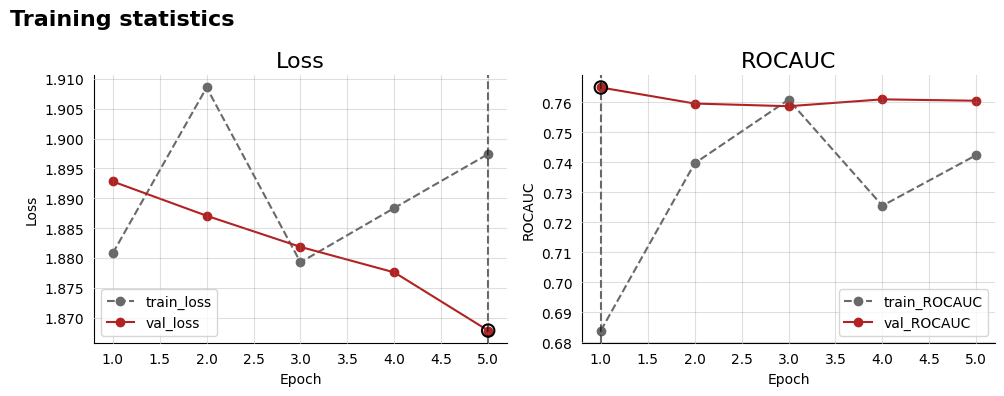

In [ ]:
monai_biotrainer.fit()

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()